In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set seed for reproducibility
np.random.seed(42)

In [51]:
# Generate client-level data
client_ids = np.arange(1, 100 + 1)

# Income: Should follow a right skewed distribution (log-normal)
# Adjusting the income distribution to follow a log-normal distribution (right-skewed, long tail)
mean_income = 10  # Log-normal mean
sigma_income = 0.6  # Log-normal standard deviation

# Generate income values (skewed distribution)
client_incomes = np.random.lognormal(mean=mean_income, sigma=sigma_income, size=100)
client_incomes = np.interp(client_incomes, (client_incomes.min(), client_incomes.max()), (20000, 200000))
print(client_incomes)



[ 94273.7838319   65646.31505413 130931.88100682  56317.73962883
  52268.69236951  36992.01725981  37714.80383559  36136.27596483
  67463.94079309  52348.565519    71618.0815394   33169.30427514
  39149.82356998  38835.07275898 200000.          55196.45179302
  58102.81413036  57769.71900555 140596.16869208  27720.57281303
  58298.13214155  27609.18459584  20399.73702706  41514.95763949
  74812.07194647  40256.09563788  74156.56318368  63592.84830807
  55958.42861632 119540.98640351  44424.51784131  73558.26115246
  25583.62713015  63336.06870302  52666.8887183   33582.66207511
  74265.3876132   41419.9662169  155677.03885471  20000.
  68541.3567718   61500.45309451  52035.65367784  45919.73724754
  62341.51998995 106747.72635592  27031.63753129  40096.98746489
  35701.41958218  34927.71054104  72080.93298108  82321.22124219
 106920.62489799  83028.6743091   86774.10156188  30273.09222743
 135192.830556    53961.05849348 105030.6102642   30757.5140481
  53093.5581935   99923.74246923  

In [53]:
income = client_incomes[14]
print(income)
income_factor = (income / 200000)
print(income_factor)

200000.0
1.0


In [82]:
def create_synthetic_csv(num_clients=100, num_transactions=1000, num_products=3, client_categories=["low_spender", "mid_spender", "high_spender"]):

    # Generate client-level data
    client_ids = np.arange(1, num_clients + 1)

    # Income: Should follow a right skewed distribution (log-normal)
    # Adjusting the income distribution to follow a log-normal distribution (right-skewed, long tail)
    mean_income = 10  # Log-normal mean
    sigma_income = 0.6  # Log-normal standard deviation

    # Generate income values (skewed distribution)
    client_incomes = np.random.lognormal(mean=mean_income, sigma=sigma_income, size=num_clients)
    client_incomes = np.interp(client_incomes, (client_incomes.min(), client_incomes.max()), (20000, 200000))

    #client_incomes = np.random.uniform(20000, 100000, size=num_clients)  # Continuous feature: income
    client_spending_categories = np.random.choice(client_categories, size=num_clients)  # Categorical feature

    # Map spending categories to a numerical effect (low = 0.8, mid = 1, high = 1.2)
    category_effects = {"low_spender": 0.8, "mid_spender": 1, "high_spender": 1.2}
    product_base_prices = {1: (10, 30), 2: (15, 50), 3: (5, 25)}

    data = []
    for _ in range(num_transactions):
        client = np.random.choice(client_ids)
        product = np.random.randint(1, num_products + 1)

        # Determine product base price range
        base_price_min, base_price_max = product_base_prices[product]
        mean_price = (base_price_min + base_price_max) / 2

        # Client attributes
        income = client_incomes[client - 1]
        category = client_spending_categories[client - 1]
        category_multiplier = category_effects[category]

        # Price is sampled randomly within the product's base range
        price = np.random.uniform(base_price_min, base_price_max)

        # Amount bought depends on price (inverse relation) and income (higher income buys more)
        base_demand = np.random.uniform(5, 20)  # Base demand per product
        income_factor = (income / 200000)  # Scaled income effect (higher income = more purchases)
        
        print("&"*50)
        print("price: ", price)
        print("mean_price: ", mean_price)
        print("price / mean_price: ", price / mean_price)
        print("(price / mean_price)**2: ", (price / mean_price)**2)
        print("(1 / (1 + (price / mean_price)**2)): ", (1 / (1 + (price / mean_price)**2)))
        print("&"*50)
        #amount_bought = max(0, (base_demand * category_multiplier * income_factor * (1 / (1 + (price / mean_price)**2))) + np.random.normal(0, 1))
        amount_bought = max(0, (base_demand * category_multiplier * income_factor * (1 / (price / mean_price)**2)) + np.random.normal(0, 1))

        data.append([client, product, price, amount_bought, income, category])

    # Create DataFrame
    df = pd.DataFrame(data, columns=["client_id", "product_id", "offered_price", "amount_bought", "income", "client_category"])
    df["amount_bought"] = df["amount_bought"].round().astype(int)
    df["amount_bought"] = df["amount_bought"].clip(lower=0)  # Ensure no negative values

    df_name_to_save = f"synthetic_dataset_{num_clients}clients_{num_transactions}trans.csv"
    df.to_csv("data/" + df_name_to_save, index=False)
    return df, df_name_to_save




In [90]:
df, df_name = create_synthetic_csv(num_clients=100, num_transactions=1000, num_products=3, client_categories=["low_spender", "mid_spender", "high_spender"])
df

&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
price:  29.973300084722492
mean_price:  20.0
price / mean_price:  1.4986650042361247
(price / mean_price)**2:  2.2459967949220636
(1 / (1 + (price / mean_price)**2)):  0.30807177676957936
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
price:  23.02932284677866
mean_price:  15.0
price / mean_price:  1.535288189785244
(price / mean_price)**2:  2.3571098256940513
(1 / (1 + (price / mean_price)**2)):  0.29787527126648566
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
price:  48.96728431370792
mean_price:  32.5
price / mean_price:  1.506685671191013
(price / mean_price)**2:  2.2701017117723135
(1 / (1 + (price / mean_price)**2)):  0.30580088576450576
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
price:  13.667023487457291
mean_price:  15.0
price / mean_price:  0.911134899163819

,client_id,product_id,offered_price,amount_bought,income,client_category
0,21,1,29.973300,1,41469.430112,high_spender
1,26,3,23.029323,2,42121.245279,mid_spender
2,62,2,48.967284,2,54110.043890,high_spender
3,95,3,13.667023,2,46590.055175,low_spender
4,36,2,31.643321,4,59701.943866,low_spender
...,...,...,...,...,...,...
995,57,2,36.482640,2,29650.568023,mid_spender
996,48,1,29.931676,2,96072.472069,high_spender
997,7,3,21.396933,1,49523.922364,mid_spender
998,32,2,43.258191,4,57956.312359,mid_spender


In [91]:
df_loaded = pd.read_csv("data/synthetic_dataset_100clients_1000trans.csv")
df_loaded

,client_id,product_id,offered_price,amount_bought,income,client_category
0,21,1,29.973300,1,41469.430112,high_spender
1,26,3,23.029323,2,42121.245279,mid_spender
2,62,2,48.967284,2,54110.043890,high_spender
3,95,3,13.667023,2,46590.055175,low_spender
4,36,2,31.643321,4,59701.943866,low_spender
...,...,...,...,...,...,...
995,57,2,36.482640,2,29650.568023,mid_spender
996,48,1,29.931676,2,96072.472069,high_spender
997,7,3,21.396933,1,49523.922364,mid_spender
998,32,2,43.258191,4,57956.312359,mid_spender


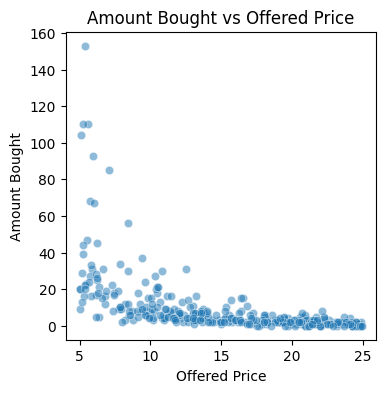

In [94]:
df_filtered = df_loaded[df_loaded['product_id'] == 3]

plt.figure(figsize=(4, 4))
sns.scatterplot(x=df_filtered["offered_price"], y=df_filtered["amount_bought"], alpha=0.5)
plt.xlabel("Offered Price")
plt.ylabel("Amount Bought")
plt.title("Amount Bought vs Offered Price")
plt.show()


In [95]:
df

,client_id,product_id,offered_price,amount_bought,income,client_category
0,21,1,29.973300,1,41469.430112,high_spender
1,26,3,23.029323,2,42121.245279,mid_spender
2,62,2,48.967284,2,54110.043890,high_spender
3,95,3,13.667023,2,46590.055175,low_spender
4,36,2,31.643321,4,59701.943866,low_spender
...,...,...,...,...,...,...
995,57,2,36.482640,2,29650.568023,mid_spender
996,48,1,29.931676,2,96072.472069,high_spender
997,7,3,21.396933,1,49523.922364,mid_spender
998,32,2,43.258191,4,57956.312359,mid_spender


In [96]:
numerical_features = ['offered_price', 'amount_bought', 'income']
categorical_features = ['client_category']

In [97]:
correlation_matrix = df[numerical_features].corr()
print(correlation_matrix)


               offered_price  amount_bought    income
offered_price       1.000000      -0.376119 -0.019446
amount_bought      -0.376119       1.000000  0.442103
income             -0.019446       0.442103  1.000000


In [61]:
correlation_price_amount = df["offered_price"].corr(df["amount_bought"])
print("Correlation between Offered Price and Amount Bought:", correlation_price_amount)


Correlation between Offered Price and Amount Bought: -0.13825596335387655


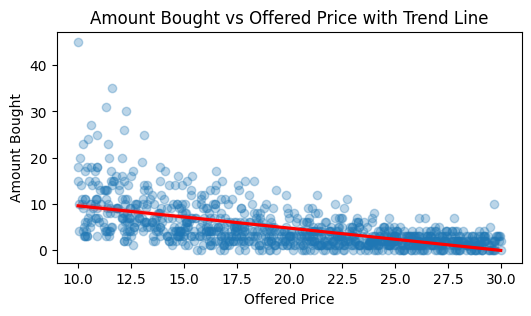

In [89]:
plt.figure(figsize=(6, 3))
sns.regplot(x=df["offered_price"], y=df["amount_bought"], scatter_kws={"alpha": 0.3}, line_kws={"color": "red"})
plt.xlabel("Offered Price")
plt.ylabel("Amount Bought")
plt.title("Amount Bought vs Offered Price with Trend Line")
plt.show()
